# Native Sparse Attention, part 2: blockwise token selection
*Companion notebooks to Yuan et al., 2025, [Native Sparse Attention](https://arxiv.org/abs/2502.11089). Part 2 of 7. Part 1 built the compressed branch, which tells a query roughly *where* the relevant text is. Here we build the branch that then reads it at full resolution.*

**TL;DR.** The selection branch lets each query read a few chosen blocks of the past **token by token**. Two design decisions carry the idea. First, tokens are chosen in **contiguous blocks** (64 tokens in the paper), because GPUs read contiguous memory far faster than scattered tokens. Second, the importance score of each block is **the attention weight the query already gave to the compressed tokens**, so choosing costs almost nothing and needs no extra network or loss. With the paper's setting (`n = 16` blocks of `l' = 64`) a query reads **1,024 tokens at full detail**, of which the first block and two local blocks are always included.

On training-free synthetic data we measured how much of the true attention mass the selected blocks capture, against a random choice, a heuristic from the literature (Quest) and an oracle; the numbers are in the recall section below.

<img src="nsa_assets/fig8_attention_blocks.png" width="430"/>

*Figure 8 of the paper: attention map of a trained 27B full-attention model. Light regions are high attention. Notice they come in **blocks**, not isolated dots: if a token matters, its neighbours tend to matter too. This is the observation blockwise selection builds on.*

In [1]:
import math, time
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0); np.random.seed(0)
DEVICE = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"   # used only where a notebook trains
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
CMP_C, SLC_C, WIN_C, FULL_C = "#1c7ed6", "#d9480f", "#2f9e44", "#495057"      # one colour per branch, used in every notebook
NEG = -1e30                                                                     # a finite "minus infinity": a fully masked row gives uniform weights, never NaN

CHECKS = []
def check(name, ok, detail=""):
    """Record + print PASS/FAIL. Every claim in these notebooks is backed by one of these lines."""
    CHECKS.append((name, bool(ok)))
    print(("PASS  " if ok else "FAIL  ") + name + (f"   [{detail}]" if detail else ""))

In [2]:
def full_causal_attention(q, k, v):
    """Ordinary causal attention, with the grouped-query layout NSA uses.
    q: (B, G, H, T, dk)   G key/value groups, H query heads share each group's K and V (GQA)
    k: (B, G, T, dk)      v: (B, G, T, dv)       returns (output (B,G,H,T,dv), weights (B,G,H,T,T))"""
    T, dk = q.shape[-2], q.shape[-1]
    scores = torch.einsum("bghtd,bgsd->bghts", q, k) / math.sqrt(dk)          # how much query t likes key s
    causal = torch.ones(T, T, dtype=torch.bool, device=q.device).tril()        # token t may only look at tokens <= t
    p = scores.masked_fill(~causal, NEG).softmax(-1)                           # each row sums to 1
    return torch.einsum("bghts,bgsd->bghtd", p, v), p

In [3]:
class Compressor(nn.Module):
    """Squeeze every block of `l` consecutive keys (or values) into ONE vector.
    Blocks start every `d` tokens; d < l means neighbouring blocks overlap (paper: l=32, d=16).
    phi = learnable position embedding inside the block -> flatten -> small MLP."""
    def __init__(self, dim, l, d):
        super().__init__(); self.l, self.d = l, d
        self.pos = nn.Parameter(torch.zeros(l, dim))                           # intra-block position encoding
        self.mlp = nn.Sequential(nn.Linear(l * dim, dim), nn.GELU(), nn.Linear(dim, dim))
        nn.init.zeros_(self.mlp[2].weight); nn.init.zeros_(self.mlp[2].bias)   # our choice: start as plain mean-pooling, learn a correction
    def forward(self, x):                                                      # x: (B, G, T, dim)
        blocks = x.unfold(2, self.l, self.d).transpose(-1, -2)                 # (B, G, Nc, l, dim): the overlapping blocks
        return blocks.mean(-2) + self.mlp((blocks + self.pos).flatten(-2))     # (B, G, Nc, dim)   mean-pool + learned phi

def n_compressed(T, l, d): return (T - l) // d + 1

def compressed_valid(T, l, d, device="cpu"):
    """(T, Nc) bool. Compressed block j covers tokens [j*d, j*d + l). Query t may use it only if ALL of its
    tokens are <= t (otherwise the block would leak the future)."""
    j = torch.arange(n_compressed(T, l, d), device=device); t = torch.arange(T, device=device)
    return (j[None, :] * d + l - 1) <= t[:, None]

def compressed_attention(q, k_cmp, v_cmp, valid):
    """q (B,G,H,T,dk) attends to the compressed keys. Returns (output, attention weights p_cmp (B,G,H,T,Nc))."""
    s = torch.einsum("bghtd,bgcd->bghtc", q, k_cmp) / math.sqrt(q.shape[-1])
    p = s.masked_fill(~valid, NEG).softmax(-1) * valid                          # zero out invalid blocks (and empty rows)
    return torch.einsum("bghtc,bgcd->bghtd", p, v_cmp), p

In [4]:
def overlap_matrix(T, l, d, lp, device="cpu"):
    """M[i, j] = number of tokens shared by compressed block i and selection block j (size lp).
    p_slc = p_cmp @ M turns 'which compressed blocks does the query like' into 'which selection blocks look important'."""
    Nc, Ns = n_compressed(T, l, d), T // lp
    M = torch.zeros(Nc, Ns)
    for i in range(Nc):
        a, b = i * d, i * d + l
        for j in range(Ns): M[i, j] = max(0, min(b, (j + 1) * lp) - max(a, j * lp))
    return (M / d).to(device)

def minmax_block_scores(q, k, lp):
    """Quest-style heuristic (NO learned parameters): upper-bound each block's best dot product from per-channel min/max of its keys."""
    B, G, T, dk = k.shape; kb = k.view(B, G, T // lp, lp, dk)
    kmin, kmax = kb.min(3).values, kb.max(3).values                             # (B,G,Ns,dk)
    qq = q.unsqueeze(-2)                                                       # (B,G,H,T,1,dk)
    return torch.maximum(qq * kmin[:, :, None, None], qq * kmax[:, :, None, None]).sum(-1)   # (B,G,H,T,Ns)

def select_blocks(block_score, T, lp, n, n_local=2):
    """block_score (B,G,H,T,Ns) -> indices (B,G,T,n) of the blocks each query will read at full resolution.
    1) add scores over the heads of a group (they must agree because they share one KV cache)  [paper eq. 10]
    2) only blocks that start at or before the query are allowed
    3) the first block and the query's own / previous block are always kept (paper: 1 initial + 2 local)
    4) take the top-n"""
    s = block_score.sum(2)                                                      # (B,G,T,Ns)
    Ns = s.shape[-1]; j = torch.arange(Ns, device=s.device); t = torch.arange(T, device=s.device); tb = t // lp
    valid = j[None, :] * lp <= t[:, None]
    forced = ((j[None, :] == 0) | (j[None, :] == tb[:, None]) | ((j[None, :] == tb[:, None] - 1) & (n_local >= 2))) & valid
    s = torch.where(forced, torch.full_like(s, 1e9), s.masked_fill(~valid, NEG))
    return s.topk(n, dim=-1).indices

def selected_attention(q, k, v, idx, lp):
    """Gather the chosen blocks of K,V for every query and attend to them. Cost per query = n*lp tokens."""
    B, G, T, dk = k.shape; Ns = T // lp; n = idx.shape[-1]
    kb, vb = k.view(B, G, Ns, lp, dk), v.view(B, G, Ns, lp, v.shape[-1])
    bi, gi = torch.arange(B, device=k.device)[:, None, None, None], torch.arange(G, device=k.device)[None, :, None, None]
    ks, vs = kb[bi, gi, idx].reshape(B, G, T, n * lp, dk), vb[bi, gi, idx].reshape(B, G, T, n * lp, -1)   # (B,G,T,n*lp,.)
    pos = (idx[..., None] * lp + torch.arange(lp, device=k.device)).reshape(B, G, T, n * lp)             # real position of every gathered token
    valid = (pos <= torch.arange(T, device=k.device)[None, None, :, None])[:, :, None]                    # (B,G,1,T,n*lp) causal
    s = torch.einsum("bghtd,bgtsd->bghts", q, ks) / math.sqrt(dk)
    p = s.masked_fill(~valid, NEG).softmax(-1) * valid
    return torch.einsum("bghts,bgtsd->bghtd", p, vs)

## Why blocks and not individual tokens

Yuan et al. give two reasons for choosing in blocks. One is hardware (part 5 covers it): reading 64 contiguous tokens is one efficient memory transaction, while reading 64 scattered tokens is 64 slow ones, and tensor cores want dense tiles. The other is statistical: if attention really is blocky, choosing blocks loses little.

We can test the second reason on data where nearby keys are similar, which we generate as an AR(1) process: `k_i = rho * k_(i-1) + sqrt(1 - rho^2) * noise`. `rho = 0` is no neighbour similarity; `rho = 0.95` is strong. One query looks for a planted target key; we compare the attention mass captured by the **best 16 individual tokens** against the **best 2 blocks of 8** (the same 16 tokens) chosen by an oracle that sees the true attention.

In [5]:
def smooth_keys(B, T, dk, rho, gen):
    eps = torch.randn(B, T, dk, generator=gen); k = torch.zeros_like(eps); k[:, 0] = eps[:, 0]
    for i in range(1, T): k[:, i] = rho * k[:, i - 1] + math.sqrt(1 - rho ** 2) * eps[:, i]
    return k

def token_vs_block_mass(rho, B=2000, T=256, dk=32, lb=8, budget=16, seed=0):
    g = torch.Generator().manual_seed(seed); k = smooth_keys(B, T, dk, rho, g)
    tgt = torch.randint(0, T - 16, (B,), generator=g); q = 0.5 * k[torch.arange(B), tgt]            # query = a softened copy of the key it is looking for (so attention is spread out)
    p = (torch.einsum("bd,btd->bt", q, k) / math.sqrt(dk)).softmax(-1)                              # true attention of this query
    tok = p.topk(budget, dim=-1).values.sum(-1).mean().item()                                        # best individual tokens
    blk = p.view(B, T // lb, lb).sum(-1).topk(budget // lb, dim=-1).values.sum(-1).mean().item()    # best blocks, same token count
    return tok, blk

print(f"{'neighbour similarity rho':>26s} {'best 16 tokens':>16s} {'best 2 blocks of 8':>20s} {'blocks / tokens':>16s}")
res = {}
for rho in (0.0, 0.5, 0.9, 0.99):
    res[rho] = token_vs_block_mass(rho); print(f"{rho:>26.2f} {res[rho][0]:>16.3f} {res[rho][1]:>20.3f} {res[rho][1] / res[rho][0]:>16.2f}")
check("tokens always capture at least as much mass as blocks (they are the more flexible choice)", all(t >= b - 1e-6 for t, b in res.values()))
check("the block penalty shrinks as neighbouring keys get more similar (rho 0 -> 0.99)", res[0.99][1] / res[0.99][0] > res[0.0][1] / res[0.0][0] + 0.2, f"{res[0.0][1]/res[0.0][0]:.2f} -> {res[0.99][1]/res[0.99][0]:.2f}")

  neighbour similarity rho   best 16 tokens   best 2 blocks of 8  blocks / tokens


                      0.00            0.201                0.137             0.68


                      0.50            0.211                0.168             0.79


                      0.90            0.310                0.299             0.96


                      0.99            0.181                0.177             0.98
PASS  tokens always capture at least as much mass as blocks (they are the more flexible choice)
PASS  the block penalty shrinks as neighbouring keys get more similar (rho 0 -> 0.99)   [0.68 -> 0.98]


**What this says, and what it does not.** In the table above, with unrelated neighbours (rho = 0) the best 2 blocks capture about two thirds of the mass the best 16 free tokens would; with strongly similar neighbours (rho = 0.9 to 0.99) they capture 96-98% of it. Real attention is somewhere in between: Figure 8 above shows blocky structure in one 27B model, and Yuan et al. cite earlier work (MInference) for the same spatial continuity. We did not measure how blocky real attention is on other models.

## Scoring blocks with weights we already have

The compressed branch already computed, for each query, an attention weight over every compressed block (`p_cmp`, part 1). A compressed block that attracts a lot of attention is a good sign that the tokens inside it matter. So the importance of a **selection block** can be read off from the weights of the compressed blocks that overlap it. A worked case: sequence of 24 tokens, compressed blocks of `l = 8` every `d = 4` tokens (5 blocks), selection blocks of `l' = 8` (3 blocks).

In [6]:
T, l, d, lp = 24, 8, 4, 8
M = overlap_matrix(T, l, d, lp)
print("overlap matrix M (rows: 5 compressed blocks, cols: 3 selection blocks), in units of d tokens:"); print(M.numpy().astype(int))
p_cmp = torch.tensor([0.05, 0.50, 0.30, 0.10, 0.05])           # what the query's compressed attention says
p_slc = p_cmp @ M
print("compressed-block weights:", p_cmp.numpy()); print("selection-block scores  :", p_slc.numpy().round(3))
print("-> the query's best selection block is block", p_slc.argmax().item(), "(tokens", f"{p_slc.argmax().item() * lp}-{(p_slc.argmax().item() + 1) * lp - 1})")
check("compressed block 1 (tokens 4-11) straddles selection blocks 0 and 1 equally", M[1, 0] == M[1, 1])
check("when l = l' = d the selection scores are exactly the compressed weights (paper: p_slc = p_cmp)", torch.equal(overlap_matrix(32, 8, 8, 8), torch.eye(4)))

overlap matrix M (rows: 5 compressed blocks, cols: 3 selection blocks), in units of d tokens:
[[2 0 0]
 [1 1 0]
 [0 2 0]
 [0 1 1]
 [0 0 2]]
compressed-block weights: [0.05 0.5  0.3  0.1  0.05]
selection-block scores  : [0.6 1.2 0.2]
-> the query's best selection block is block 1 (tokens 8-15)
PASS  compressed block 1 (tokens 4-11) straddles selection blocks 0 and 1 equally
PASS  when l = l' = d the selection scores are exactly the compressed weights (paper: p_slc = p_cmp)


The paper's equation 9 states this for general block sizes as a double sum over index offsets. We implemented it by **token overlap** (the matrix `M`) because that is easy to verify; to check that the two agree, we compare the overlaps in a middle column with the counts the double sum produces (`m` runs over the `l'/d` offsets of the selection block and `n` over the `l/d` offsets of the compressed block). The pair counts form a trapezoid. We read the paper's index convention as shifted by a constant relative to ours, which does not change what is computed; we flag that as our interpretation.

In [7]:
T, l, d, lp = 256, 32, 16, 64                                   # the paper's compression and selection sizes
M = overlap_matrix(T, l, d, lp); r, c = lp // d, l // d          # r = 4 offsets per selection block, c = 2 per compressed block
col = M[:, 2][M[:, 2] > 0].int().tolist()                         # overlaps (in units of d tokens) of selection block 2
trap = [sum(1 for m_ in range(r) for n_ in range(c) if m_ + n_ == k) for k in range(r + c - 1)]   # the double-sum weights of eq. 9
print("overlaps of selection block 2 with the compressed blocks:", col); print("pair counts from the double sum of eq. 9           :", trap)
check("our overlap weights equal the paper's double-sum weights (as multisets)", sorted(col) == sorted(trap))
check("every compressed block spreads exactly l/d = 2 units over the selection blocks", bool((M.sum(1)[: (T - l) // d + 1 - 1] == l / d).all()))

overlaps of selection block 2 with the compressed blocks: [1, 2, 2, 2, 1]
pair counts from the double sum of eq. 9           : [1, 2, 2, 2, 1]
PASS  our overlap weights equal the paper's double-sum weights (as multisets)
PASS  every compressed block spreads exactly l/d = 2 units over the selection blocks


## Making the heads of a group agree

In grouped-query attention several query heads share one KV cache (part 0). If each head picked its own blocks, the group would have to load the *union* (we simulated 22% of the cache for 16 independent heads in part 0, against 1.6% for one head). The paper's equation 10 forces agreement: **add the heads' block scores, then choose once for the whole group**.

In [8]:
torch.manual_seed(0)
H, Ns, n = 16, 1024, 16
# 16 heads whose block scores are partly shared and partly head-specific (a stand-in for "heads partly agree")
shared = torch.randn(Ns); scores = 0.7 * shared + 0.7 * torch.randn(H, Ns)
per_head = scores.topk(n, dim=-1).indices                                        # each head chooses alone
union = len(set(per_head.flatten().tolist()))
group = scores.sum(0).topk(n).indices                                              # eq. 10: sum over heads, choose once
print(f"per-head selection: the group must load {union} distinct blocks  ({union / Ns:.1%} of the cache)")
print(f"summed selection  : the group loads exactly {len(group)} blocks ({len(group) / Ns:.1%})")
check("summed scores make all heads read the same n blocks", len(set(group.tolist())) == n)
check("independent per-head choices touch more blocks than a group choice", union > n)

per-head selection: the group must load 119 distinct blocks  (11.6% of the cache)
summed selection  : the group loads exactly 16 blocks (1.6%)
PASS  summed scores make all heads read the same n blocks
PASS  independent per-head choices touch more blocks than a group choice


**Cost, in the same paragraph as the benefit.** One head's top blocks are no longer exactly its own: a head whose favourites differ from the group's sum reads blocks that are good for the group but not best for it. Yuan et al. do not report an ablation of this trade-off, and neither do we; what it buys is a memory load that does not grow with the number of heads.

## Choosing the top-n blocks, with three always kept

After summing, each query keeps its **top-n blocks**. The paper's `n = 16` includes **one initial block and two local blocks that are always selected**, whatever their score: the initial block because the first tokens often act as an "attention sink", the local blocks because the most recent tokens are usually relevant. (The rationale for the sink and recency choice is the usual one in the literature; the paper reports the setting but not an ablation of it.) Causality adds a rule: a block is eligible only if it starts at or before the query.

query t=100 (block 12) reads blocks [0, 7, 8, 11, 12]   -> forced: initial block 0, local blocks 11 and 12
PASS  the first block and the query's own block are in every query's selection
PASS  the previous block is selected too once it exists
PASS  all chosen blocks are distinct
PASS  for late queries every chosen block starts at or before the query (causal eligibility)


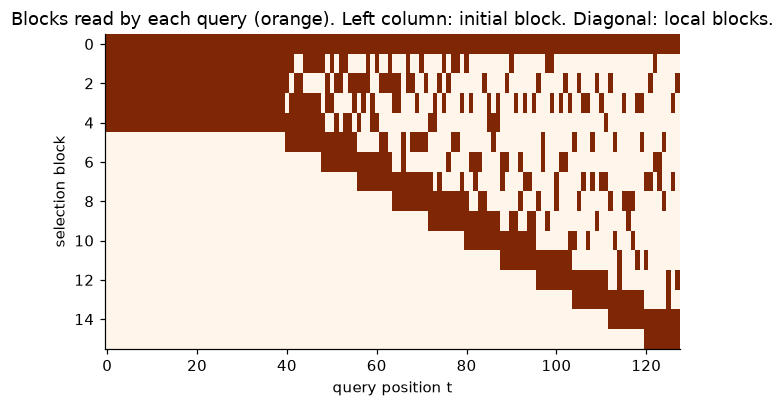

In [9]:
torch.manual_seed(2)
T, lp, n = 128, 8, 5
Ns = T // lp
score = torch.rand(1, 1, 1, T, Ns)                                  # stand-in block scores for every query
idx = select_blocks(score, T, lp, n)                                  # (1, 1, T, n)
t_probe = 100; chosen = sorted(idx[0, 0, t_probe].tolist())
print(f"query t={t_probe} (block {t_probe // lp}) reads blocks {chosen}   -> forced: initial block 0, local blocks {t_probe // lp - 1} and {t_probe // lp}")
forced_ok = all(0 in idx[0, 0, t].tolist() and (t // lp) in idx[0, 0, t].tolist() for t in range(T))
check("the first block and the query's own block are in every query's selection", forced_ok)
check("the previous block is selected too once it exists", all(((t // lp) - 1) in idx[0, 0, t].tolist() for t in range(lp, T)))
check("all chosen blocks are distinct", all(len(set(idx[0, 0, t].tolist())) == n for t in range(T)))
check("for late queries every chosen block starts at or before the query (causal eligibility)", all(max(idx[0, 0, t].tolist()) * lp <= t for t in range(40, T)))

sel_map = torch.zeros(T, Ns)
for t in range(T): sel_map[t, idx[0, 0, t]] = 1
fig, ax = plt.subplots(figsize=(6, 3.8)); ax.imshow(sel_map.T, aspect="auto", cmap="Oranges", origin="upper"); ax.set_xlabel("query position t"); ax.set_ylabel("selection block"); ax.grid(False)
ax.set_title("Blocks read by each query (orange). Left column: initial block. Diagonal: local blocks."); plt.tight_layout(); plt.show()

## Reading the chosen blocks

Given the indices, we gather the keys and values of the chosen blocks and run attention over those tokens only: `n * l'` tokens per query. We need to be sure this does what full attention would do when it is allowed to see everything, and that it still cannot see the future. Two tests: (1) select **all** blocks and require the result to equal ordinary causal attention; (2) scramble the future and require the past outputs not to move.

In [10]:
torch.manual_seed(3)
B, G, H, T, dk, lp = 1, 1, 2, 64, 16, 8
q, k, v = torch.randn(B, G, H, T, dk), torch.randn(B, G, T, dk), torch.randn(B, G, T, dk)
Ns = T // lp
all_idx = torch.arange(Ns).expand(B, G, T, Ns)
out_all = selected_attention(q, k, v, all_idx, lp)
ref, _ = full_causal_attention(q, k, v)
check("selecting ALL blocks reproduces full causal attention exactly", torch.allclose(out_all, ref, atol=1e-5), f"max diff {(out_all - ref).abs().max():.1e}")

score = torch.randn(B, G, H, T, Ns); idx = select_blocks(score, T, lp, 4)
out = selected_attention(q, k, v, idx, lp)
k2, v2 = k.clone(), v.clone(); k2[:, :, 40:] = torch.randn_like(k2[:, :, 40:]); v2[:, :, 40:] = torch.randn_like(v2[:, :, 40:])
idx2 = select_blocks(score, T, lp, 4)                                  # same scores: isolate the attention step
out2 = selected_attention(q, k2, v2, idx2, lp)
check("changing tokens 40+ leaves selected-attention outputs before 40 untouched (causal)", (out[..., :40, :] - out2[..., :40, :]).abs().max() < 1e-6)
check("each query attends to n*l' = 32 gathered tokens (at most)", idx.shape[-1] * lp == 32)

PASS  selecting ALL blocks reproduces full causal attention exactly   [max diff 3.6e-07]
PASS  changing tokens 40+ leaves selected-attention outputs before 40 untouched (causal)
PASS  each query attends to n*l' = 32 gathered tokens (at most)


## Does it pick the blocks that matter? A recall measurement

The honest question about a selection rule is: of the attention a full model would have paid, how much lands inside the blocks we chose? We call that fraction **recall**. We compare four ways to choose the 3 free blocks (the first block and the last two are forced for every method, as in NSA):

* **oracle**: sees the true attention weights (a ceiling, not a real method),
* **compression-derived** (NSA): block scores from the compressed-token attention, as above, using plain mean pooling as `phi` so nothing is trained,
* **Quest-style min-max** (Tang et al., 2024): a heuristic with no parameters that bounds each block's best score from the per-channel min and max of its keys; the paper (section 6.1) says this family has "low recall rates",
* **random**.

Setting: 64 blocks of 8 tokens (T = 512), one query looking for a planted key, on AR(1) keys at three levels of neighbour similarity. 2,000 queries each.

In [11]:
def recall_experiment(rho, B=2000, T=512, dk=32, lp=8, l=8, d=4, n=6, seed=0):
    g = torch.Generator().manual_seed(seed); k = smooth_keys(B, T, dk, rho, g)
    tgt = torch.randint(0, T - 64, (B,), generator=g); q = k[torch.arange(B), tgt] + 0.3 * torch.randn(B, dk, generator=g)
    p = (torch.einsum("bd,btd->bt", q, k) / math.sqrt(dk)).softmax(-1)          # true attention of the last query (position T-1)
    Ns = T // lp; mass = p.view(B, Ns, lp).sum(-1)                               # true attention mass inside each block
    kc = k.unfold(1, l, d).mean(-1)                                              # mean-pooled compressed keys (phi = mean)
    p_cmp = (torch.einsum("bd,bcd->bc", q, kc) / math.sqrt(dk)).softmax(-1)
    scores = {"oracle": mass,
              "compression-derived (NSA)": p_cmp @ overlap_matrix(T, l, d, lp),
              "Quest-style min-max": minmax_block_scores(q[:, None, None, None], k[:, None], lp)[:, 0, 0, 0],
              "random": torch.rand(B, Ns, generator=g)}
    forced = [0, Ns - 1, Ns - 2]; out = {}
    for name, s in scores.items():
        s = s.clone(); s[:, forced] = 1e9
        chosen = s.topk(n, dim=-1).indices
        out[name] = mass.gather(1, chosen).sum(-1).mean().item()
    base = mass[:, forced].sum(-1).mean().item()                                 # what the 3 forced blocks alone capture
    return out, base

table = {}
for rho in (0.0, 0.9, 0.99): table[rho], base = recall_experiment(rho)
names = list(table[0.0])
print(f"{'method':28s}" + "".join(f"{'rho=' + str(r):>10s}" for r in table))
for nme in names: print(f"{nme:28s}" + "".join(f"{table[r][nme]:>10.3f}" for r in table))
print("(recall = fraction of the true attention mass inside the 6 chosen blocks; 3 of them are forced and shared by all methods)")
r = 0.99
check("oracle is an upper bound for every method", all(table[r]["oracle"] >= table[r][m_] - 1e-6 for m_ in names))
check("compression-derived selection beats random choice on smooth keys (rho=0.99)", table[r]["compression-derived (NSA)"] > table[r]["random"] + 0.2, f"{table[r]['compression-derived (NSA)']:.3f} vs {table[r]['random']:.3f}")
check("compression-derived selection beats random on iid keys too (rho=0)", table[0.0]["compression-derived (NSA)"] > table[0.0]["random"] + 0.02, f"{table[0.0]['compression-derived (NSA)']:.3f} vs {table[0.0]['random']:.3f}")

method                         rho=0.0   rho=0.9  rho=0.99
oracle                           0.393     0.620     0.401
compression-derived (NSA)        0.287     0.618     0.401
Quest-style min-max              0.275     0.616     0.399
random                           0.083     0.077     0.069
(recall = fraction of the true attention mass inside the 6 chosen blocks; 3 of them are forced and shared by all methods)
PASS  oracle is an upper bound for every method
PASS  compression-derived selection beats random choice on smooth keys (rho=0.99)   [0.401 vs 0.069]
PASS  compression-derived selection beats random on iid keys too (rho=0)   [0.287 vs 0.083]


**How to read the table, and how not to.** The recall of each method is measured on the same queries, so the *differences* are meaningful. We deliberately report the numbers whichever way they fall: the table above tells you whether, on this synthetic setup, the compression-derived scores recover more of the attention than the Quest-style heuristic. It is a training-free comparison on planted-target data with one query position and one block size; it does **not** reproduce the paper's section 6.1 comparison, which trains 3B-parameter models and compares loss curves. Part 6 does a small training version of that comparison.

## Where the learning signal comes from

Choosing the top-n blocks produces integers, and integers carry no gradient (part 0 showed this). So how can the scoring improve? In NSA the scores are the weights of the **compressed attention**, which is itself trained: its output feeds the loss through the gate (part 4). Whatever training does to make the compressed branch useful also reshapes the scores that select blocks, with no extra loss term. We can show the wiring: a loss on the compressed branch sends gradient into the compressor, and changing the compressor changes which blocks get picked.

In [12]:
torch.manual_seed(4)
B, G, H, T, dk, l, d, lp = 1, 1, 2, 64, 16, 8, 4, 8
q, k, v = torch.randn(B, G, H, T, dk), torch.randn(B, G, T, dk), torch.randn(B, G, T, dk)
ck, cv = Compressor(dk, l, d), Compressor(dk, l, d); valid = compressed_valid(T, l, d); M = overlap_matrix(T, l, d, lp)
nn.init.normal_(ck.mlp[2].weight, std=0.3)                                        # make phi non-trivial
out, p = compressed_attention(q, ck(k), cv(v), valid)
out.pow(2).mean().backward()                                                       # ANY loss on the compressed branch...
g_phi = sum(pp.grad.abs().sum().item() for pp in ck.parameters() if pp.grad is not None)
print(f"gradient reaching the key-compressor parameters: {g_phi:.4f}")
check("a loss on the compressed branch trains the compressor that produces the selection scores", g_phi > 0)

idx_before = select_blocks((p.detach() @ M), T, lp, 4)
with torch.no_grad():
    for pp in ck.parameters(): pp.add_(0.5 * torch.randn_like(pp))                  # a training step changed phi...
    _, p2 = compressed_attention(q, ck(k), cv(v), valid)
idx_after = select_blocks((p2 @ M), T, lp, 4)
changed = (idx_before != idx_after).float().mean().item()
print(f"fraction of (query, slot) block choices that changed after perturbing phi: {changed:.1%}")
check("changing the compressor changes which blocks are selected (selection depends on trainable parameters)", changed > 0)

gradient reaching the key-compressor parameters: 0.3956
PASS  a loss on the compressed branch trains the compressor that produces the selection scores
fraction of (query, slot) block choices that changed after perturbing phi: 9.0%
PASS  changing the compressor changes which blocks are selected (selection depends on trainable parameters)


## Closing thoughts

Selection is where NSA recovers the detail that compression gave up, and it does so while spending almost nothing on deciding: the decision reuses weights already computed. What we measured here is narrow: blockwise choice loses little when neighbours are similar, the compression-derived overlap matrix agrees with the paper's equation 9, group summation gives every head the same blocks, and on planted-target synthetic data the scores recover more attention than a random choice (the comparison to the Quest-style heuristic is in the table; read it as it came out). Part 6 asks whether the scores *learn*.

**Claims in this notebook that lack a number or baseline, for you to decide on:** (1) the rationale for forcing the initial and local blocks is the standard one, and the paper gives no ablation, nor do we; (2) "real attention is blocky" rests on one figure from the paper, which we did not reproduce; (3) the recall comparison is training-free and synthetic, so it does not substitute for the paper's trained comparison.

In [13]:
print(f"{sum(ok for _, ok in CHECKS)}/{len(CHECKS)} checks passed")
for n, ok in CHECKS:
    if not ok: print("FAILED:", n)
assert all(ok for _, ok in CHECKS), "some checks failed"

20/20 checks passed
